# Parte 4 — Machine Learning e conclusões

Nesta parte desenvolvemos uma regressão logística para classificar `high_risk_flag`, avaliamos o modelo com métricas e matriz de confusão e apresentamos a aplicação das previsões e as conclusões do trabalho. Foi corrigida apenas a sequência de execução, colocando o treino antes da matriz de confusão.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data = pd.read_csv("data/dataset_prog.csv", sep=";")

## Machine Learning- Regressão Logística

Como algoritmo de previsão utilizámos o modelo de regressão logística. Neste, optámos por prever a variável high_risk_flag, que indica se o utilizador está em situação de risco elevado ou não. Para tal, utilizámos variáveis relacionadas com o comportamento digital, tais como horas de ecrã, notificações e nº de horas de ecrã, tendo em vista o objetivo de identificar padrões que possam prever este risco. 

## Desempenho do modelo

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

data = pd.read_csv("data/dataset_prog.csv", sep=";")

X = data[['device_hours_per_day', 'phone_unlocks', 'notifications_per_day',
        'social_media_mins', 'sleep_hours', 'stress_level']]

y = data['high_risk_flag']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8414285714285714
              precision    recall  f1-score   support

           0       0.85      0.97      0.91       559
           1       0.76      0.31      0.44       141

    accuracy                           0.84       700
   macro avg       0.80      0.64      0.67       700
weighted avg       0.83      0.84      0.81       700



O algoritmo apresenta uma precisão de 0.84, isto é, acerta cerca de 84% das classificações. 
Relativamente à classe 0, de baixo risco, este apresenta uma precisão de 0.85, evidenciando que está correto 85% das vezes. Em relação à sensibilidade, este apresenta uma percentagem de 97%, que mostra que este identifica quase todos os utilizadores que são de baixo risco. Por fim, possui um f1-score igual a 0.91, que demonstra um excelente desempenho geral nesta classe.
Em relação à classe 1, temos que esta possui uma precisão de 0.76, para identificar utilizadores de alto risco. Contudo, a nível da sensibilidade, este identifica apenas 31% dos casos. Isto resulta num f1-score de 0.44, o que demonstra que o algoritmo apresenta dificuldades na identificação de utilizadores de alto risco. 
Posto isto, podemos concluir que o algoritmo possui uma boa capacidade para identificar utilizadores que não se encontram num cenário de alto risco, mas revela uma menor sensibilidade para detetar indivíduos potencialmente vulneráveis. Este resultado sugere que, apesar das variáveis digitais e psicológicas utilizadas possuírem um elevado poder preditivo, a assimetria entre classes (que resulta do facto de existirem mais utilizadores de baixo risco do que de alto risco) condiciona a sensibilidade do mesmo.

## Matriz de confusão

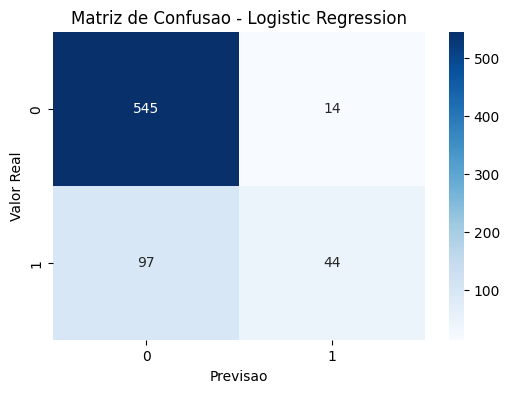

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

data = pd.read_csv("data/dataset_prog.csv", sep=";")

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusao - Logistic Regression")
plt.xlabel("Previsao")
plt.ylabel("Valor Real")
plt.show()

A matriz de confusão avalia o desempenho do modelo, relativamente à capacidade de este identificar se um utilizador apresenta um risco elevado de desenvolver problemas de saúde mental com base nos seus padrões de comportamento digital.
O modelo previu corretamente 545 utilizadores que não são de alto risco (verdadeiro negativo= 545), bem como previu corretamente 44 utilizadores que são de alto risco (verdadeiro positivo=44). Contudo, este previu 14 utilizadores que eram de alto risco, mas na realidade não eram (falsos positivos= 14), bem como previu que 97 utilizadores que eram de baixo risco, mas na verdade eram de alto risco (falso negativo= 97).

## Aplicação do algoritmo

Através do modelo treinado, estimámos a probabilidade de cada utilizador pertencer ao grupo de alto risco numa escala de 0 a 1. Sendo que 1 é o mais provável e 0 não é provável. Na seguinte tabela apresentamos os primeiros 10 utilizadores, mostrando como o modelo atribui diferentes níveis de risco com base nos padrões de comportamento digital e bem-estar mental.

In [ ]:
data['prob_risco'] = model.predict_proba(X)[:, 1]   
data['class_preditiva'] = model.predict(X)          

data[['prob_risco', 'class_preditiva']].head(10)

,prob_risco,class_preditiva
0,0.077294,0
1,0.080761,0
2,0.170659,0
3,0.090213,0
4,0.569957,1
5,0.025938,0
6,0.173907,0
7,0.090946,0
8,0.072487,0
9,0.030969,0


A análise realizada permite constatar que existem claros padrões que distinguem os utilizadores com maior risco de desenvolver uma doença mental daqueles que não têm. Os utilizadores classificados como alto risco, apresentam uma maior exposição digital, isto é, mais horas de ecrã, mais notificações, mais desbloqueios e maior tempo nas redes sociais. Não obstante, possuem ainda piores indicadores de sono, níveis de stress mais elevados, ansiedade e sintomas depressivos.
A regressão lógica, confirmou que variáveis como device_hours_per_day, sleep_quality, anxiety_score, stress_level e digital_dependence_score, são as mais relevantes para a previsão do risco. No entanto, apesar do modelo apresentar uma maior capacidade para identificar utilizadores de baixo risco, fornece indicadores importantes sobre os comportamentos e condições associadas à vulnerabilidade psicológica.
Concluindo, o estudo evidencia que padrões de utilização digital intensiva, combinados com a fragilidade emocional e má qualidade de sono, estão associados a um maior risco de desenvolver problemas de saúde mental. Estes resultados reforçam a importância da promoção de hábitos digitais equilibrados, maior literacia digital e estratégias preventivas focadas no bem-estar psicológico.  